In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings
import joblib
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import random

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kyleahmurphy/uk-electrical-load")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\stros\.cache\kagglehub\datasets\kyleahmurphy\uk-electrical-load\versions\2


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import seasonal_decompose
import kagglehub

# 1) Download & unpack
dataset_dir = kagglehub.dataset_download("kyleahmurphy/uk-electrical-load")

# 2) Find all the CSVs
csv_files = [f for f in os.listdir(dataset_dir) if f.endswith(".csv")]
print("Available files:", csv_files)

# 3) Read each one, tag it, reset_index → Time
all_dfs = []
for fn in csv_files:
    path = os.path.join(dataset_dir, fn)
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    df = df.reset_index().rename(columns={'index':'Time'})

    all_dfs.append(df)

# 4) Concat into one big DataFrame
combined_df = pd.concat(all_dfs, ignore_index=True)


Available files: ['House_1.csv', 'House_10.csv', 'House_11.csv', 'House_12.csv', 'House_13.csv', 'House_15.csv', 'House_16.csv', 'House_17.csv', 'House_18.csv', 'House_19.csv', 'House_2.csv', 'House_20.csv', 'House_21.csv', 'House_3.csv', 'House_4.csv', 'House_5.csv', 'House_6.csv', 'House_7.csv', 'House_8.csv', 'House_9.csv']


In [ ]:
import pandas as pd

for i, df in enumerate(all_dfs, start=1):
    # 1) Keep only the two columns
    df = df[['Time', 'Aggregate']].copy()

    # 2) Ensure Time is a datetime
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')

    # 3) Compute span
    t_min = df['Time'].min()
    t_max = df['Time'].max()

    # 4) Print shape and span
    print(f"Series #{i}: shape={df.shape}, time span={t_min} → {t_max}")


Series #1: shape=(6960008, 2), time span=2013-10-09 13:06:17 → 2015-07-10 11:56:32
Series #2: shape=(6739284, 2), time span=2013-11-20 11:31:18 → 2015-06-30 11:07:07
Series #3: shape=(4431541, 2), time span=2014-06-03 11:36:21 → 2015-06-30 15:12:08
Series #4: shape=(5859544, 2), time span=2014-03-07 10:52:15 → 2015-07-08 02:10:54
Series #5: shape=(4737371, 2), time span=2014-01-17 22:26:20 → 2015-05-31 11:06:07
Series #6: shape=(6225696, 2), time span=2013-12-17 17:24:18 → 2015-07-08 02:10:54
Series #7: shape=(5722544, 2), time span=2014-01-10 10:58:19 → 2015-07-08 02:10:54
Series #8: shape=(5431577, 2), time span=2014-03-06 16:23:19 → 2015-06-19 14:52:18
Series #9: shape=(5007721, 2), time span=2014-03-07 10:33:18 → 2015-05-24 11:34:04
Series #10: shape=(5622610, 2), time span=2014-03-06 16:23:19 → 2015-06-20 03:32:54
Series #11: shape=(5733526, 2), time span=2013-09-17 22:08:11 → 2015-05-28 08:05:43
Series #12: shape=(5168605, 2), time span=2014-03-20 12:01:19 → 2015-06-23 19:44:00
S

In [45]:
# 1) Define your downsize + resample function:
import pandas as pd

def downsize_and_resample(df, months, freq='15T'):
    df2 = df[['Time','Aggregate']].copy()
    df2['Time'] = pd.to_datetime(df2['Time'], errors='coerce')
    df2 = df2.set_index('Time').sort_index()
    
    # slice last N months
    end   = df2.index.max()
    start = end - pd.DateOffset(months=months)
    window = df2.loc[start:end]
    
    # resample into freq buckets
    agg_window = window.resample(freq).mean().dropna(subset=['Aggregate'])
    return agg_window

# 2) Apply to all_dfs and collect results:
processed_dfs = []
for i, df in enumerate(all_dfs, start=1):
    small = downsize_and_resample(df, months=12, freq='15T')
    processed_dfs.append(small)
    print(f"Series #{i}: {small.shape[0]} rows, "
          f"{small.index.min()} → {small.index.max()}")

# Now `processed_dfs` is a list of 20 DataFrames, each one the last 4 months in 15 min bins.
processed_map = {
    fn: downsize_and_resample(df, months=12, freq='15T')
    for fn, df in zip(csv_files, all_dfs)
}


Series #1: 31821 rows, 2014-07-10 11:45:00 → 2015-07-10 11:45:00
Series #2: 31866 rows, 2014-06-30 11:00:00 → 2015-06-30 11:00:00
Series #3: 31001 rows, 2014-06-30 15:00:00 → 2015-06-30 15:00:00
Series #4: 32173 rows, 2014-07-08 02:00:00 → 2015-07-08 02:00:00
Series #5: 28858 rows, 2014-05-31 11:00:00 → 2015-05-31 11:00:00
Series #6: 31221 rows, 2014-07-08 02:00:00 → 2015-07-08 02:00:00
Series #7: 29069 rows, 2014-07-08 02:00:00 → 2015-07-08 02:00:00
Series #8: 32395 rows, 2014-06-19 14:45:00 → 2015-06-19 14:45:00
Series #9: 32617 rows, 2014-05-24 11:30:00 → 2015-05-24 11:30:00
Series #10: 32395 rows, 2014-06-20 03:30:00 → 2015-06-20 03:30:00
Series #11: 32492 rows, 2014-05-28 08:00:00 → 2015-05-28 08:00:00
Series #12: 32459 rows, 2014-06-23 19:30:00 → 2015-06-23 19:30:00
Series #13: 30768 rows, 2014-07-10 11:45:00 → 2015-07-10 11:45:00
Series #14: 32773 rows, 2014-06-02 10:45:00 → 2015-06-02 10:45:00
Series #15: 31383 rows, 2014-07-07 09:45:00 → 2015-07-07 09:45:00
Series #16: 32397 r

In [46]:
for i, df in enumerate(processed_dfs, start=1):
    df.reset_index(inplace=True)          # brings the index into a column named 'Time'
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    print(f"Series #{i} now has columns: {df.columns.tolist()}")


Series #1 now has columns: ['Time', 'Aggregate']
Series #2 now has columns: ['Time', 'Aggregate']
Series #3 now has columns: ['Time', 'Aggregate']
Series #4 now has columns: ['Time', 'Aggregate']
Series #5 now has columns: ['Time', 'Aggregate']
Series #6 now has columns: ['Time', 'Aggregate']
Series #7 now has columns: ['Time', 'Aggregate']
Series #8 now has columns: ['Time', 'Aggregate']
Series #9 now has columns: ['Time', 'Aggregate']
Series #10 now has columns: ['Time', 'Aggregate']
Series #11 now has columns: ['Time', 'Aggregate']
Series #12 now has columns: ['Time', 'Aggregate']
Series #13 now has columns: ['Time', 'Aggregate']
Series #14 now has columns: ['Time', 'Aggregate']
Series #15 now has columns: ['Time', 'Aggregate']
Series #16 now has columns: ['Time', 'Aggregate']
Series #17 now has columns: ['Time', 'Aggregate']
Series #18 now has columns: ['Time', 'Aggregate']
Series #19 now has columns: ['Time', 'Aggregate']
Series #20 now has columns: ['Time', 'Aggregate']


In [ ]:

# 5) Your plotting function (fixed “Time” vs “time” and FFT freq calc)
def plot_time_series_with_differencing_and_fft(df, variable='Aggregate',
                                               differencing=False,
                                               aggregation_period=None):
    # ensure datetime
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    
    # fill & flag missing
    mean_val = df[variable].mean()
    missing_mask = df[variable].isna()
    df_clean = df.copy()
    df_clean[variable] = df_clean[variable].fillna(mean_val)
    
    # differencing
    if differencing:
        df_clean[variable] = df_clean[variable].diff()
    df_clean = df_clean.dropna(subset=[variable])
    
    # optional aggregation
    if aggregation_period:
        # truncate so length % agg == 0
        L = len(df_clean)
        df_clean = df_clean.iloc[: (L // aggregation_period)*aggregation_period ]
        df_clean = df_clean.groupby(
            np.arange(len(df_clean)) // aggregation_period
        ).agg({variable:'mean', 'Time':'first'})
    
    # interactive time-series + missing markers
    trace_clean = go.Scatter(
        x=df_clean['Time'], y=df_clean[variable],
        mode='lines', name=variable
    )
    trace_missing = go.Scatter(
        x=df.loc[missing_mask,'Time'],
        y=[mean_val]*missing_mask.sum(),
        mode='markers', name='Missing',
        marker=dict(color='red', symbol='x', size=8)
    )
    fig = go.Figure([trace_clean, trace_missing])
    fig.update_layout(
        title=f"Time series {variable}",
        xaxis_rangeslider_visible=True,
        xaxis_title="Time", yaxis_title=variable
    )
    fig.show()

    # seasonal_decompose
    decomposition = seasonal_decompose(df_clean[variable],
                                      model='additive', period=24)
    fig2, axes = plt.subplots(4,1,figsize=(10,8))
    decomposition.observed.plot(ax=axes[0], title="Observed")
    decomposition.trend.plot(ax=axes[1],    title="Trend")
    decomposition.seasonal.plot(ax=axes[2], title="Seasonal")
    decomposition.resid.plot(ax=axes[3],    title="Residual")
    plt.tight_layout()
    plt.show()
    
    # FFT
    # recalc sampling freq from 'Time'
    dt = df_clean['Time'].diff().dt.total_seconds().mean()
    fs = 1.0 / dt
    signal = df_clean[variable].values
    n = len(signal)
    fft_res = np.fft.fft(signal)
    freq   = np.fft.fftfreq(n, d=1/fs)
    
    fft_shift = np.fft.fftshift(fft_res)
    freq_shift= np.fft.fftshift(freq)
    
    plt.figure(figsize=(10,6))
    plt.plot(freq_shift[n//2:], np.abs(fft_shift[n//2:]))
    plt.xscale('log')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.title(f"FFT of {variable}")
    plt.grid(which='both', linestyle='--', linewidth=0.5)
    plt.show()


for i, df in enumerate(processed_dfs, start=1):
    # 1) sort by time and reset integer index
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    df2 = df[['Time','Aggregate']].copy()
    df2['Time'] = pd.to_datetime(df2['Time'], errors='coerce')
    df2 = df2.sort_values('Time').reset_index(drop=True)

    N = len(df2)
    window_size = max(1, int(N * x))         # at least 1 point
    start = random.randint(0, N - window_size)
    window = df2.iloc[start : start + window_size]

    # 2) set up the series for ts-plots
    ts = window.set_index('Time')['Aggregate']

    # 3) ACF & PACF
    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    plot_acf(ts,   lags=50, ax=axes[0], title=f"Series #{i} ACF (window={window_size} pts)")
    plot_pacf(ts,  lags=50, ax=axes[1], title=f"Series #{i} PACF (window={window_size} pts)")
    plt.tight_layout()
    plt.show()

    plot_time_series_with_differencing_and_fft(
        df,
        variable='Aggregate',
        differencing=False,
        aggregation_period=1
    )


"\nplot_time_series_with_differencing_and_fft(\n        all_dfs[5],\n        variable='Aggregate',\n        differencing=False,\n        aggregation_period=1\n    )\n\n    "

In [48]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd

def preprocess_df(df):
    """
    Preprocess a single DataFrame with only 'Time' & 'Aggregate':
      - Report % missing
      - Parse & sort 'Time'
      - Create hour/minute/second/day/month features
    """
    print("Missing values (% of col):")
    print((df.isnull().mean() * 100).round(2))
    print("Columns:", df.columns.tolist(), "\n")
    
    # 1) Parse Time
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    if df['Time'].isnull().any():
        print("⚠️  Some Time values became NaT!")
    
    # 2) Sort & reset
    df = df.sort_values('Time').reset_index(drop=True)
    
    # 3) Time‐based features
    df['hour']   = df['Time'].dt.hour
    df['minute'] = df['Time'].dt.minute
    df['second'] = df['Time'].dt.second
    df['day']    = df['Time'].dt.day
    df['month']  = df['Time'].dt.month
    
    return df

def add_lag_features(df, column, lag_freqs=None):
    """
    Add:
      - 1‐row lag of `column`
      - time‐based lags for each freq in lag_freqs (dict suffix→freq string)
    """
    df = df.copy()
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    df = df.sort_values('Time').reset_index(drop=True)
    
    # Simple 1‐row lag
    df[f'{column}_lag_1'] = df[column].shift(1)
    
    # Time‐based lags
    if lag_freqs is None:
        lag_freqs = {
            '1h':  '1H',
            '24h': '24H',
            '168h':'168H'
        }
    for suffix, freq_str in lag_freqs.items():
        shift_col = f'time_minus_{suffix}'
        df[shift_col] = df['Time'] - pd.Timedelta(freq_str)
        
        temp = df[['Time', column]].rename(
            columns={column: f'{column}_{suffix}'}
        )
        df = pd.merge_asof(
            df.sort_values(shift_col),
            temp.sort_values('Time'),
            left_on=shift_col,
            right_on='Time',
            direction='backward',
            tolerance=pd.Timedelta(freq_str)
        )
        df.drop(columns=[shift_col, 'Time_y'], inplace=True)
        df.rename(columns={'Time_x':'Time'}, inplace=True)
    
    return df


In [66]:
# assuming preprocess_df() and add_lag_features() are already defined as above

all_lagged = []

for idx, df in enumerate(processed_dfs, start=1):
    print(f"\n--- Series #{idx} ---")
    
    # 1) re-preprocess just in case (parses Time & adds hour/minute/etc)
    clean = preprocess_df(df)
    
    # 2) add only the 1-row, 1h, 24h & 168h lags on 'Aggregate'
    lagged = add_lag_features(
        clean,
        column='Aggregate',
        lag_freqs={
            '1h':   '1H',
            '24h':  '24H',
            '168h': '168H'
        }
    )
    
    print("Result cols:", lagged.columns.tolist())
    print("Sample:\n", lagged.head(2), "\n")
    
    all_lagged.append(lagged)

# Now all_lagged is a list of DataFrames—one per original series—with your lag features.



--- Series #1 ---
Missing values (% of col):
Time         0.0
Aggregate    0.0
dtype: float64
Columns: ['Time', 'Aggregate'] 

Result cols: ['Time', 'Aggregate', 'hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
Sample:
                  Time   Aggregate  hour  minute  second  day  month  \
0 2014-07-10 11:45:00  219.888889    11      45       0   10      7   
1 2014-07-10 12:00:00  288.291045    12       0       0   10      7   

   Aggregate_lag_1  Aggregate_1h  Aggregate_24h  Aggregate_168h  
0              NaN           NaN            NaN             NaN  
1       219.888889           NaN            NaN             NaN   


--- Series #2 ---
Missing values (% of col):
Time         0.0
Aggregate    0.0
dtype: float64
Columns: ['Time', 'Aggregate'] 

Result cols: ['Time', 'Aggregate', 'hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
Sample:
               

In [72]:
import numpy as np

def create_supervised_data_from_series(df, input_features, target_feature,
                                       window_size=1, step=1):
    X, y = [], []
    for i in range(window_size, len(df), step):
        # grab a 1×len(input_features) window
        window_data = df.iloc[i-window_size:i][input_features].values.flatten()
        X.append(window_data)
        y.append(df.iloc[i][target_feature])
    return np.array(X), np.array(y)

# PARAMETERS
target_feature = 'Aggregate'
window_size   = 1
step          = 1
train_count   = 4032    # as before

training_datasets = []
testing_datasets  = []

for idx, ts in enumerate(all_lagged, start=1):
    # 1) Sort, reset index
    df = ts.sort_values('Time').reset_index(drop=True)
    
    # 2) Pick your features (everything except Time & target)
    input_features = [c for c in df.columns if c not in ['Time', target_feature]]
    print(f"Series {idx}: using features={input_features}")
    
    # 3) Drop any row with NaN in any feature or the target
    df = df.dropna(subset=input_features + [target_feature])
    
    # 4) Build supervised arrays
    X_all, y_all = create_supervised_data_from_series(
        df, input_features, target_feature,
        window_size=window_size, step=step
    )
    
    # 5) Split into train/test
    X_train = X_all[:train_count]
    y_train = y_all[:train_count]
    X_test  = X_all[train_count:]
    y_test  = y_all[train_count:]
    
    print(f"  → X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
    
    training_datasets.append({'X_train': X_train, 'y_train': y_train})
    testing_datasets .append({'X_test':  X_test,  'y_test':  y_test})


Series 1: using features=['hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
  → X_train shape: (4032, 9), y_train shape: (4032,)
Series 2: using features=['hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
  → X_train shape: (4032, 9), y_train shape: (4032,)
Series 3: using features=['hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
  → X_train shape: (4032, 9), y_train shape: (4032,)
Series 4: using features=['hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
  → X_train shape: (4032, 9), y_train shape: (4032,)
Series 5: using features=['hour', 'minute', 'second', 'day', 'month', 'Aggregate_lag_1', 'Aggregate_1h', 'Aggregate_24h', 'Aggregate_168h']
  → X_train shape: (4032, 9), y_train shape: (4032,)
Series 6: using features=['hour', '

In [84]:
joblib.dump(training_datasets,  "training_datasets.joblib")
joblib.dump(testing_datasets,   "testing_datasets.joblib")

['testing_datasets.joblib']

In [82]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    'n_estimators': [50, 70, 100, 120 ],
    'max_depth':    [3, 5],
    'learning_rate':[0.01, 0.1]
}
from sklearn.model_selection import TimeSeriesSplit

batch_size = 30
# Use 3 splits of your training data, each testing exactly 30 points
tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=batch_size,
    gap=0
)


best_gbdt_models = []
best_params_list  = []

for idx, data in enumerate(training_datasets, start=1):
    X_train = data['X_train']
    y_train = data['y_train']
    print(f"\nTuning Series #{idx} (train size = {X_train.shape[0]}, features = {X_train.shape[1]})…")
    
    base = GradientBoostingRegressor(random_state=42)
    grid = GridSearchCV(
        estimator   = base,
        param_grid  = param_grid,
        cv          = tscv,
        scoring     = 'neg_root_mean_squared_error',
        n_jobs      = 1,
        verbose     = 1
    )
    grid.fit(X_train, y_train)
    
    best_gbdt_models.append(grid.best_estimator_)
    best_params_list .append(grid.best_params_)
    
    print(f" → Best params: {grid.best_params_}")
    print(f" → CV RMSE: {-grid.best_score_:.4f}")

print(f"\nDone. Trained {len(best_gbdt_models)} GBDT models.")



Tuning Series #1 (train size = 4032, features = 9)…
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 120}
 → CV RMSE: 393.2133

Tuning Series #2 (train size = 4032, features = 9)…
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
 → CV RMSE: 305.9067

Tuning Series #3 (train size = 4032, features = 9)…
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 70}
 → CV RMSE: 329.5543

Tuning Series #4 (train size = 4032, features = 9)…
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
 → CV RMSE: 380.3900

Tuning Series #5 (train size = 4032, features = 9)…
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_

In [85]:
joblib.dump(best_gbdt_models,  "best_gbdt_models.joblib")
joblib.dump(best_params_list,   "best_gbdt_params.joblib")

print("GBDT models and params saved.")

# …later, in a new session…
best_gbdt_models = joblib.load("best_gbdt_models.joblib")
best_params_list  = joblib.load("best_gbdt_params.joblib")
print("Reloaded", len(best_gbdt_models), "GBDT models.")


GBDT models and params saved.
Reloaded 20 GBDT models.


In [ ]:
import sys, os

# 1) Add your project root (parent of `src/`) to sys.path

project_root = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2) Import your module object
from src.ensemble_methods import elasticGBDT
from src.ensemble_methods import AccuracyUpdatedGBDT 

# 3) Reload it when you’ve made changes
import importlib
importlib.reload(elasticGBDT)
importlib.reload(AccuracyUpdatedGBDT)

# 4) Now you can re-import classes from it if you like
from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.AccuracyUpdatedGBDT import AccuracyUpdatedGBDT

In [ ]:
from sklearn.metrics import root_mean_squared_error  
from itertools import product
# 1) Load your pretrained base GBDTs + saved datasets
best_gbdt_models   = joblib.load("best_gbdt_models.joblib")
training_datasets  = joblib.load("training_datasets.joblib")
testing_datasets   = joblib.load("testing_datasets.joblib")

# 2) Hyperparameter grids
index_grid = {
    'm_threshold':         [38],
    'dynamic_rebuild':     [True, False],
    'fixed_rebuild_count': [2, 5, 7]
}

contrib_grid = {
    'm_threshold':            [0],
    'ratio_fixed_multiplier': [0.5, 1.0],
    'alpha_multiplier':       [0.5, 1.0],
    'beta_multiplier':        [0.2, 0.4],
    'gamma_multiplier':       [0.1, 0.2]
}

ratio_grid = {
    'm_threshold':            [0],
    'ratio_fixed_multiplier': [1.0, 1.5, 2.0, 2.5],
}

accuracy_grid = {
    'error_damping':         [0.1, 0.2, 0.3,0.4 ],
    'reg_coef':              [ 1.0, 1.5, 2, 2.5],
    'weight_threshold_ratio':[0.05, 0.1]
}

def expand(grid):
    keys = list(grid)
    for vals in product(*(grid[k] for k in keys)):
        yield dict(zip(keys, vals))

# 3) Tuning settings
batch_size     = 30
n_tune_batches = 45

tuned_index_models    = []
tuned_contrib_models  = []
tuned_ratio_models    = []
tuned_accuracy_models = []

# 4) Loop over each series
for ts_idx in range(len(best_gbdt_models)):
    print(f"\n=== Series {ts_idx} ===")
    base    = best_gbdt_models[ts_idx]
    y_train = training_datasets[ts_idx]['y_train']
    X_test, y_test = (testing_datasets[ts_idx][k] for k in ('X_test', 'y_test'))

    n_batches = X_test.shape[0] // batch_size
    n_tune    = min(n_batches, n_tune_batches)

    # ——— Index-Based ———
    best_rmse, best_cfg = np.inf, None
    for cfg in expand(index_grid):
        m = ElasticGBDT(pretrained_model=base, y_train=y_train, m_threshold=cfg['m_threshold'], error_metric=root_mean_squared_error)
        total_err = 0.0
        for b in range(n_tune):
            s, e = b*batch_size, (b+1)*batch_size
            Xb, yb = X_test[s:e], y_test[s:e]
            total_err += root_mean_squared_error(yb, m.predict(Xb))
            before = len(m.trees)
            m.update_index_based(Xb, yb)
            pruned = before - len(m.trees)
            if cfg['dynamic_rebuild']:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), number_of_incremental_trees=pruned)
            else:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), number_of_incremental_trees=cfg['fixed_rebuild_count'])
        rmse = total_err / n_tune
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, cfg

    print("→ Index-Based best:", best_cfg, "RMSE:", best_rmse)
    tuned_index = ElasticGBDT(pretrained_model=base, y_train=y_train, m_threshold=best_cfg['m_threshold'], error_metric=root_mean_squared_error)
    tuned_index.dynamic_rebuild = best_cfg['dynamic_rebuild']
    tuned_index.fixed_rebuild   = best_cfg['fixed_rebuild_count']
    tuned_index_models.append(tuned_index)

    # ——— Contribution-Weighted-Ratio ———
    best_rmse, best_cfg = np.inf, None
    for cfg in expand(contrib_grid):
        m = ElasticGBDT(
            pretrained_model=base,
            y_train=y_train,
            error_metric=root_mean_squared_error,
            m_threshold=cfg['m_threshold'],
            ratio_fixed_multiplier=cfg['ratio_fixed_multiplier'],
            alpha_multiplier=cfg['alpha_multiplier'],
            beta_multiplier=cfg['beta_multiplier'],
            gamma_multiplier=cfg['gamma_multiplier']
        )
        total_err = 0.0
        for b in range(n_tune):
            s, e = b*batch_size, (b+1)*batch_size
            Xb, yb = X_test[s:e], y_test[s:e]
            total_err += root_mean_squared_error(yb, m.predict(Xb))
            m.update_contribution_weighted_ratio(
                Xb, yb
            )
        rmse = total_err / n_tune
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, cfg

    print("→ Contrib-Weighted best:", best_cfg, "RMSE:", best_rmse)
    tuned_contrib = ElasticGBDT(pretrained_model=base, y_train=y_train, error_metric=root_mean_squared_error, **best_cfg)
    tuned_contrib_models.append(tuned_contrib)

    # ——— Ratio-Based ———
    best_rmse, best_cfg = np.inf, None
    for cfg in expand(ratio_grid):
        m = ElasticGBDT(
            pretrained_model=base,
            y_train=y_train,
            error_metric=root_mean_squared_error,
            m_threshold=cfg['m_threshold'],
            ratio_fixed_multiplier=cfg['ratio_fixed_multiplier']
        )
        total_err = 0.0
        for b in range(n_tune):
            s, e = b*batch_size, (b+1)*batch_size
            Xb, yb = X_test[s:e], y_test[s:e]
            total_err += root_mean_squared_error(yb, m.predict(Xb))
            m.update_ratio_based(Xb, yb)
        rmse = total_err / n_tune
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, cfg

    print("→ Ratio-Based best:", best_cfg, "RMSE:", best_rmse)
    tuned_ratio = ElasticGBDT(pretrained_model=base, y_train=y_train, error_metric=root_mean_squared_error, **best_cfg)
    tuned_ratio_models.append(tuned_ratio)

    # ——— AccuracyUpdatedGBDT ———
    best_rmse, best_cfg = np.inf, None
    for cfg in expand(accuracy_grid):
        m = AccuracyUpdatedGBDT(
            pretrained_model=base,
            y_train=y_train,
            error_metric=root_mean_squared_error,
            error_damping=cfg['error_damping'],
            reg_coef=cfg['reg_coef'],
            weight_threshold_ratio=cfg['weight_threshold_ratio']
        )
        m.weights = np.ones(len(m.trees))
        total_err = 0.0
        for b in range(n_tune):
            s, e = b*batch_size, (b+1)*batch_size
            Xb, yb = X_test[s:e], y_test[s:e]
            total_err += root_mean_squared_error(yb, m.predict(Xb))
            m.update_weights_by_contribution_rel(Xb, yb)
        rmse = total_err / n_tune
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, cfg

    print("→ AccuracyUpdatedGBDT best:", best_cfg, "RMSE:", best_rmse)
    tuned_acc = AccuracyUpdatedGBDT(
        pretrained_model=base,
        y_train=y_train,
        error_metric=root_mean_squared_error,
        **best_cfg
    )
    tuned_acc.weights = np.ones(len(tuned_acc.trees))
    tuned_accuracy_models.append(tuned_acc)

# 5) Save tuned models
os.makedirs("saved_models", exist_ok=True)
for i,m in enumerate(tuned_index_models, 1):
    joblib.dump(m, f"saved_models/index_based_{i}.joblib")
for i,m in enumerate(tuned_contrib_models, 1):
    joblib.dump(m, f"saved_models/contrib_weighted_{i}.joblib")
for i,m in enumerate(tuned_ratio_models, 1):
    joblib.dump(m, f"saved_models/ratio_based_{i}.joblib")
for i,m in enumerate(tuned_accuracy_models, 1):
    joblib.dump(m, f"saved_models/accuracy_updated_{i}.joblib")

print("\nAll models saved with RMSE tuning in ./saved_models/")



=== Series 0 ===
[Index-Based] Best tree index = 103, Error = 388.4878
[Index-Based] 103 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree index = 0, Error = 299.0218
[Index-Based] 0 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree index = 5, Error = 525.6609
[Index-Based] 5 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree index = 119, Error = 63.5342
[Index-Based] Pruned 0 trees. Now 120 remain.
[Index-Based] Best tree index = 0, Error = 295.3813
[Index-Based] 0 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree index = 0, Error = 33.5879
[Index-Based] 0 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree index = 0, Error = 744.1028
[Index-Based] 0 < 118 -> Full retraining.
Retraining triggered.
Retrained with 120 trees.
[Index-Based] Best tree inde

TypeError: ElasticGBDT.update_contribution_weighted_ratio() got an unexpected keyword argument 'fixed_multiplier'

In [ ]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import joblib

param_grid = {
    'n_estimators': [50, 70, 100, 120],
    'max_depth':    [3, 5],
    'learning_rate':[0.01, 0.1]
}

batch_size = 30
n_extra_batches = 45

final_plain_models = []
final_plain_params = []

for idx, data in enumerate(training_datasets, start=1):
    X_train, y_train = data['X_train'], data['y_train']
    X_test,  y_test  = testing_datasets[idx-1]['X_test'], testing_datasets[idx-1]['y_test']
    
    # how many full batches we actually have
    n_batches = X_test.shape[0] // batch_size
    extra_batches = min(n_extra_batches, n_batches)
    n_extra = extra_batches * batch_size

    # 1) carve off the first 23 batches from test
    X_extra, y_extra = X_test[:n_extra], y_test[:n_extra]

    # 2) form the expanded "training" set for tuning
    X_tune = np.vstack([X_train, X_extra])
    y_tune = np.concatenate([y_train, y_extra])

    print(f"\nSeries {idx}: tuning on {X_tune.shape[0]} samples "
          f"({len(X_train)} orig + {n_extra} extra)...")

    # 3) use TimeSeriesSplit with test_size = batch_size
    tscv = TimeSeriesSplit(n_splits=3, test_size=batch_size, gap=0)

    base = GradientBoostingRegressor(random_state=42)
    grid = GridSearchCV(
        estimator  = base,
        param_grid = param_grid,
        cv         = tscv,
        scoring    = 'neg_root_mean_squared_error',
        n_jobs     = 1,
        verbose    = 1
    )
    grid.fit(X_tune, y_tune)

    print(f" → Best params: {grid.best_params_}")
    print(f" → CV RMSE:    {-grid.best_score_:.4f}")

    final_plain_models.append(grid.best_estimator_)
    final_plain_params.append(grid.best_params_)

# save them for later
joblib.dump(final_plain_models, "final_plain_models.joblib")
joblib.dump(final_plain_params, "final_plain_params.joblib")
print(f"\nStored {len(final_plain_models)} final_plain_models.")



Series 1: tuning on 4722 samples (4032 orig + 690 extra)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
 → CV RMSE:    223.2152

Series 2: tuning on 4722 samples (4032 orig + 690 extra)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
 → CV RMSE:    129.4456

Series 3: tuning on 4722 samples (4032 orig + 690 extra)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
 → CV RMSE:    145.4682

Series 4: tuning on 4722 samples (4032 orig + 690 extra)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100}
 → CV RMSE:    317.0532

Series 5: tuning on 4722 samples (4032 orig + 690 extra)...
Fitting 3 folds for each of 16 candidates, totalling

In [125]:
import joblib
import glob
import os
import time
import numpy as np
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Settings
batch_size      = 30
n_extra_batches = 23  # first 23 batches reserved

# 1) Load models & data
final_plain_models    = joblib.load("final_plain_models.joblib")
tuned_index_models    = [joblib.load(p) for p in sorted(glob.glob("saved_models/index_based_*.joblib"))]
tuned_contrib_models  = [joblib.load(p) for p in sorted(glob.glob("saved_models/contrib_weighted_*.joblib"))]
tuned_ratio_models    = [joblib.load(p) for p in sorted(glob.glob("saved_models/ratio_based_*.joblib"))]
tuned_accuracy_models = [joblib.load(p) for p in sorted(glob.glob("saved_models/accuracy_updated_*.joblib"))]

training_datasets = joblib.load("training_datasets.joblib")
testing_datasets  = joblib.load("testing_datasets.joblib")

model_groups = {
#    "Plain":    final_plain_models,
#    "Index":    tuned_index_models,
#    "Contrib":  tuned_contrib_models,
#    "Ratio":    tuned_ratio_models,
    "Accuracy": tuned_accuracy_models
}

# storage
runtimes    = {name: [] for name in model_groups}
rmse_scores = {name: [] for name in model_groups}

colors = px.colors.qualitative.Plotly

# 2) Loop over each series
for idx in range(len(final_plain_models)):
    X_test = testing_datasets[idx]["X_test"]
    y_test = testing_datasets[idx]["y_test"]
    n_batches = X_test.shape[0] // batch_size

    # subplot with secondary y-axis
    fig = make_subplots(specs=[[{"secondary_y": True}]],
                        subplot_titles=[f"Series {idx+1}: Trees Deleted & Batch RMSE"])
    
    for j, (name, models) in enumerate(model_groups.items()):
        model = models[idx]
        color = colors[j % len(colors)]

        # reset model state
        if hasattr(model, "weights"):
            model.weights = np.ones(len(model.trees))

        deletion_counts = []
        error_counts    = []
        
        t0 = time.time()
        for b in range(n_batches):
            s, e = b*batch_size, (b+1)*batch_size
            Xb, yb = X_test[s:e], y_test[s:e]

            preds = model.predict(Xb)
            err = root_mean_squared_error(yb, preds)
            error_counts.append(err)

            if name != "Plain":
                before = len(model.trees)
                # update
                if name == "Index":
                    model.update_index_based(Xb, yb)
                elif name == "Contrib":
                    model.update_contribution_weighted_ratio(
                        Xb, yb
                    )
                elif name == "Ratio":
                    model.update_ratio_based(Xb, yb)
                elif name == "Accuracy":
                    model.update_weights_by_contribution_rel(Xb, yb)
                after = len(model.trees)
                pruned = before - after
                deletion_counts.append(pruned)
                # rebuild
                residuals = yb - model.predict(Xb)
                if name == "Index":
                    if getattr(model, "dynamic_rebuild", False):
                        n_build = pruned
                    else:
                        n_build = getattr(model, "fixed_rebuild_count", 0)
                else:
                    n_build = pruned
                if n_build > 0:
                    model.build_incremental_trees(
                        Xb, residuals,
                        number_of_incremental_trees=n_build
                    )
            else:
                deletion_counts.append(0)

        runtimes[name].append(time.time() - t0)

        # plot trees-deleted
        fig.add_trace(
            go.Scatter(
                x=list(range(1, n_batches+1)),
                y=deletion_counts,
                mode="lines+markers",
                name=f"{name} deletions",
                line=dict(color=color),
                marker=dict(color=color),
                opacity=0.6
            ),
            secondary_y=False
        )
        # plot batch RMSE
        fig.add_trace(
            go.Scatter(
                x=list(range(1, n_batches+1)),
                y=error_counts,
                mode="lines",
                name=f"{name} RMSE",
                line=dict(color=color, dash="dash"),
                opacity=0.6
            ),
            secondary_y=True
        )

        # final RMSE on held-out portion
        extra = min(n_extra_batches, n_batches) * batch_size
        X_eval, y_eval = X_test[extra:], y_test[extra:]
        if len(y_eval) > 0:
            y_pred = model.predict(X_eval)
            rmse_scores[name].append(
                np.sqrt(mean_squared_error(y_eval, y_pred))
            )

    fig.update_layout(
        title=f"Series {idx+1}: Trees Deleted & Batch RMSE",
        xaxis_title="Batch Number",
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
    )
    fig.update_yaxes(title_text="Trees Deleted", secondary_y=False)
    fig.update_yaxes(title_text="Batch RMSE", secondary_y=True)
    fig.show()

# 3) Aggregate stats
avg_runtime = {n: np.mean(runtimes[n])   for n in runtimes}
avg_rmse    = {n: np.mean(rmse_scores[n]) for n in rmse_scores}
std_rmse    = {n: np.std(rmse_scores[n])  for n in rmse_scores}

df_stats = {
    "Model":       list(avg_runtime.keys()),
    "Avg Runtime": list(avg_runtime.values()),
    "Avg RMSE":    [avg_rmse[m] for m in avg_runtime],
    "RMSE Std":    [std_rmse[m] for m in avg_runtime]
}

# 4) Plot average runtime
fig_rt = px.bar(
    df_stats,
    x="Model", y="Avg Runtime",
    title="Average Processing Time per Series",
)
fig_rt.show()

# 5) Plot accuracy with error bars
fig_acc = px.bar(
    df_stats,
    x="Model", y="Avg RMSE",
    error_y="RMSE Std",
    title="Model Accuracy (RMSE) Across Series"
)
fig_acc.show()


KeyboardInterrupt: 

Model params: {'alpha': 0.9, 'max_depth': 3, 'random_state': 42, 'eps': 1e-08, 'buffer_size': 30, 'error_damping': 1.5, 'reg_coef': 1.5, 'weight_threshold_ratio': 0.1}
Removing trees at indices [8, 12, 22] due to low relative weight.
Removing trees at indices [5, 9, 11] due to low relative weight.
Removing trees at indices [1, 2, 8] due to low relative weight.
Removing trees at indices [9, 13, 14, 45, 57] due to low relative weight.
Removing trees at indices [1, 95] due to low relative weight.
Removing trees at indices [0, 1] due to low relative weight.
Removing trees at indices [1, 4, 6, 7, 8, 10, 15, 61, 76, 84] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [63] due to low relative weight.
Removing trees at indices [11] due to low relative weight.
Removing trees at indices [19] due to low relative weight.
Removing trees at indices [0, 72] due to low relative wei

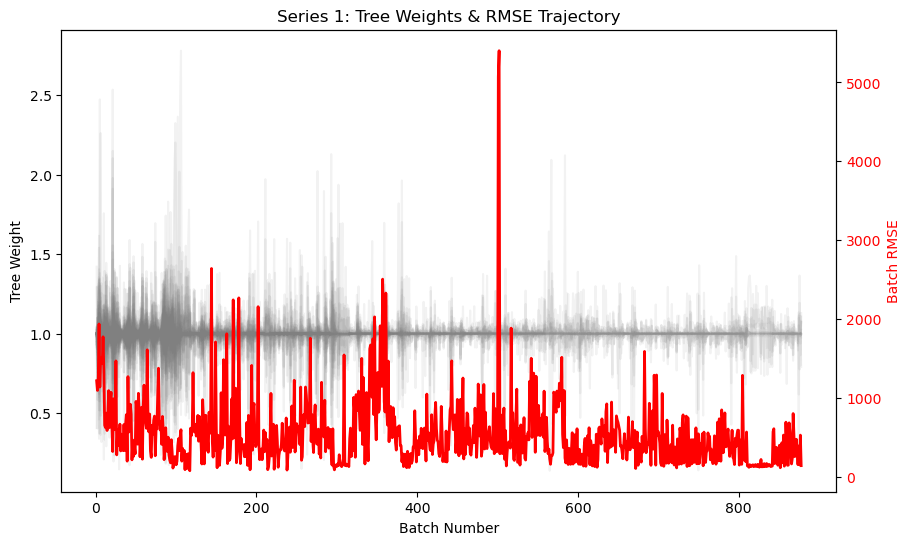

Model params: {'alpha': 0.9, 'max_depth': 5, 'random_state': 42, 'eps': 1e-08, 'buffer_size': 30, 'error_damping': 1.5, 'reg_coef': 1.0, 'weight_threshold_ratio': 0.1}
Removing trees at indices [0, 1] due to low relative weight.
Removing trees at indices [0, 1] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [3] due to low relative weight.
Removing trees at indices [20, 85] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [1, 3] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [61] due to low relative weight.
Removing trees at indices [33] due to low relative weight.
Removing trees at indices [2, 3, 6, 7, 12, 18, 20, 21] due to low relative weight.
Removing trees at indices [0, 1, 2, 3, 24] due to low relative weight.
Removing trees at indice

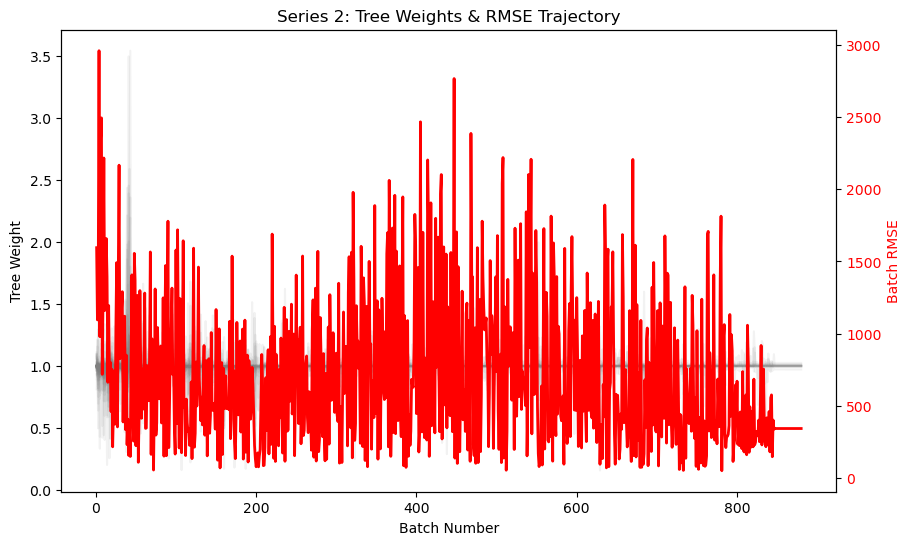

Model params: {'alpha': 0.9, 'max_depth': 3, 'random_state': 42, 'eps': 1e-08, 'buffer_size': 30, 'error_damping': 1.5, 'reg_coef': 0.7, 'weight_threshold_ratio': 0.1}
Removing trees at indices [3] due to low relative weight.
Removing trees at indices [0, 1] due to low relative weight.
Removing trees at indices [1] due to low relative weight.
Removing trees at indices [4] due to low relative weight.
Removing trees at indices [3] due to low relative weight.
Removing trees at indices [22] due to low relative weight.
Removing trees at indices [2] due to low relative weight.
Removing trees at indices [5] due to low relative weight.


KeyboardInterrupt: 

In [134]:
import joblib
import glob
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Settings
batch_size = 30
n_extra_batches = 45  # first 23 batches reserved

# Load models & test data (assumes these variables are in your environment)
paths = sorted(glob.glob("saved_models/accuracy_updated_*.joblib"))
models = [joblib.load(p) for p in paths]
testing_datasets = joblib.load("testing_datasets.joblib")  # adjust path if needed

for idx, model in enumerate(models):

    print("Model params:", model.params_)
    # Load test set
    X_test = testing_datasets[idx]["X_test"]
    y_test = testing_datasets[idx]["y_test"]
    n_batches = X_test.shape[0] // batch_size

    # Original tree count & reset weights
    N0 = len(model.trees)
    model.weights = np.ones(N0)

    # Storage arrays
    weights_over_time = np.full((n_batches, N0), np.nan)
    rmse_per_batch = []

    # Iterate batches
    for b in range(n_batches):
        s, e = b*batch_size, (b+1)*batch_size
        Xb, yb = X_test[s:e], y_test[s:e]

        # Predict + compute RMSE
        preds = model.predict(Xb)
        rmse = np.sqrt(mean_squared_error(yb, preds))
        rmse_per_batch.append(rmse)

        # Update weights
        model.update_weights_by_contribution_rel(Xb, yb)

        # Pad back to original tree count
        w = model.weights
        padded = np.concatenate([w, np.full(N0 - len(w), np.nan)])
        weights_over_time[b, :] = padded

    # Plot
    fig, ax1 = plt.subplots(figsize=(10, 6))
    # Tree weights
    for t in range(N0):
        ax1.plot(range(1, n_batches+1), weights_over_time[:, t],
                 color='gray', alpha=0.1)
    ax1.set_xlabel('Batch Number')
    ax1.set_ylabel('Tree Weight')
    ax1.set_title(f'Series {idx+1}: Tree Weights & RMSE Trajectory')

    # RMSE on secondary axis
    ax2 = ax1.twinx()
    ax2.plot(range(1, n_batches+1), rmse_per_batch,
             color='red', linewidth=2)
    ax2.set_ylabel('Batch RMSE', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    plt.show()
